In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 
from adjustText import adjust_text

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x : ast.literal_eval(x) if pd.notna(x) else x)

In [ ]:
df_india_anal = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'India')].copy()

In [11]:
df_exploded = df_india_anal.explode('job_skills').copy()
df_exploded = df_exploded.dropna(subset='salary_year_avg')
df_skills = df_exploded.groupby('job_skills')['salary_year_avg'].agg(['count', 'median'])
df_skills = df_skills[df_skills['count'] > 10]
df_skills = df_skills.rename(columns={'count' : 'skill_count', 'median' : 'median_salary'})
df_skills.sort_values(by='skill_count', ascending=False)

,skill_count,median_salary
job_skills,,
sql,46,96050.0
excel,39,98500.0
python,36,96050.0
tableau,20,108087.5
r,18,79200.0
power bi,17,111175.0
azure,15,93600.0
aws,12,79200.0
oracle,11,79200.0


In [18]:
da_jobs_total = len(df_india_anal)
df_skills['skill_percent'] = df_skills['skill_count'] / da_jobs_total * 10000
df_skills

,skill_count,median_salary,skill_percent
job_skills,,,
aws,12,79200.0,19.604640
azure,15,93600.0,24.505800
excel,39,98500.0,63.715079
oracle,11,79200.0,17.970920
power bi,17,111175.0,27.773240
python,36,96050.0,58.813919
r,18,79200.0,29.406960
spark,11,111175.0,17.970920
sql,46,96050.0,75.151119


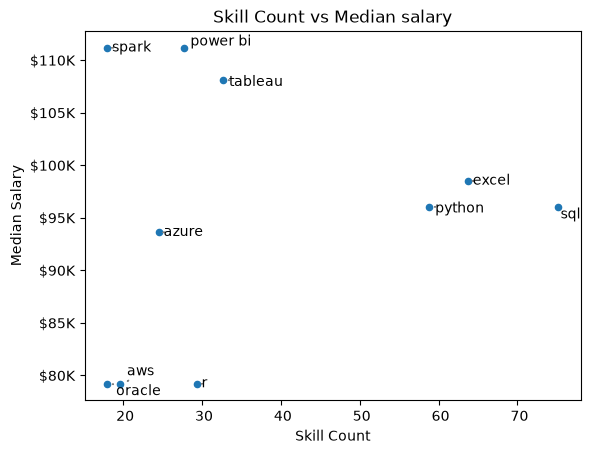

In [28]:
df_skills.plot(kind='scatter', x='skill_percent', y='median_salary')
plt.xlabel('Skill Count')
plt.ylabel('Median Salary')
texts=[]

for i, skill in enumerate(df_skills.index):
    x = df_skills['skill_percent'].iloc[i] + 0.5
    y = df_skills['median_salary'].iloc[i]
    texts.append(plt.text(x, y, skill, va='center'))
    plt.title('Skill Count vs Median salary')
    
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos : f'${int(y/1000)}K')) 
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'{int(x): ,}'))   
# : , inside the f-string formats the integer with a thousands separator (commas).
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray', lw=1))
plt.show()

In [34]:
df_technology = df_india_anal['job_type_skills'].copy()
df_technology = df_technology.drop_duplicates()
df_technology = df_technology.dropna()

In [41]:
tech_dict = {}
for row in df_technology :
    row_dict = ast.literal_eval(row)
    for key, value in row_dict.items() :
        if key in tech_dict :
            tech_dict[key] += value
        else :
            tech_dict[key] = value
            

for key, value in tech_dict.items() :
    tech_dict[key] = list(set(value))
            
tech_dict

{'analyst_tools': ['ssis',
  'sharepoint',
  'power bi',
  'alteryx',
  'sheets',
  'splunk',
  'spss',
  'excel',
  'looker',
  'ssrs',
  'datarobot',
  'qlik',
  'sap',
  'ms access',
  'visio',
  'powerbi',
  'dax',
  'sas',
  'word',
  'nuix',
  'powerpoint',
  'tableau',
  'microstrategy',
  'cognos',
  'outlook',
  'spreadsheet'],
 'cloud': ['openstack',
  'ibm cloud',
  'oracle',
  'aws',
  'redshift',
  'firebase',
  'databricks',
  'watson',
  'azure',
  'gcp',
  'vmware',
  'snowflake',
  'bigquery',
  'aurora',
  'digitalocean'],
 'programming': ['nosql',
  'c++',
  'java',
  'dart',
  'solidity',
  'vba',
  't-sql',
  'assembly',
  'mongo',
  'no-sql',
  'php',
  'c',
  'swift',
  'bash',
  'go',
  'javascript',
  'groovy',
  'scala',
  'mongodb',
  'shell',
  'r',
  'perl',
  'visual basic',
  'matlab',
  'fortran',
  'vb.net',
  'julia',
  'sas',
  'powershell',
  'golang',
  'ruby',
  'sql',
  'c#',
  'typescript',
  'crystal',
  'python',
  'css',
  'kotlin',
  'html'],

In [47]:
df_tech = pd.DataFrame(list(tech_dict.items()), columns=(['technology', 'skills']))

df_tech = df_tech.explode('skills')

In [53]:
df_skills_tech = df_skills.merge(df_tech, left_on='job_skills', right_on='skills')
df_skills_tech

,skill_count,median_salary,skill_percent,technology,skills
0,12,79200.0,19.604640,cloud,aws
1,15,93600.0,24.505800,cloud,azure
2,39,98500.0,63.715079,analyst_tools,excel
3,11,79200.0,17.970920,cloud,oracle
4,17,111175.0,27.773240,analyst_tools,power bi
5,36,96050.0,58.813919,programming,python
6,18,79200.0,29.406960,programming,r
7,11,111175.0,17.970920,libraries,spark
8,46,96050.0,75.151119,programming,sql
9,20,108087.5,32.674400,analyst_tools,tableau


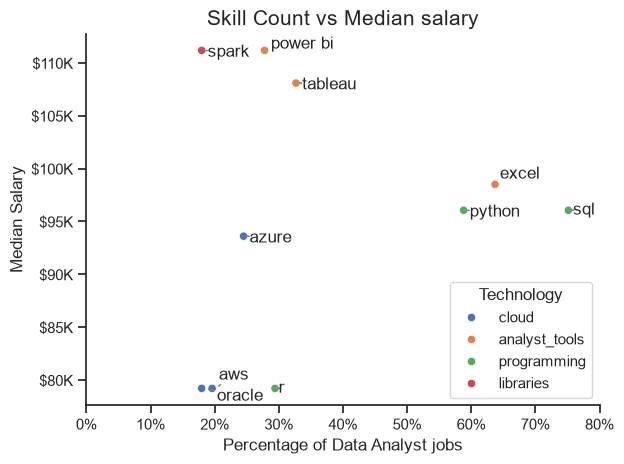

In [ ]:
#df_skills.plot(kind='scatter', x='skill_percent', y='median_salary')
import seaborn as sns
from matplotlib.ticker import PercentFormatter
sns.scatterplot(data=df_skills_tech, x='skill_percent', y='median_salary', hue='technology')
sns.despine()
sns.set_theme(style='ticks')

plt.xlabel('Percentage of Data Analyst jobs')
plt.ylabel('Median Salary')
plt.legend(loc='lower right', title='Technology')
plt.xlim(0, 80)

texts=[]

for i, skill in enumerate(df_skills.index):
    x = df_skills['skill_percent'].iloc[i] + 0.5
    y = df_skills['median_salary'].iloc[i]
    texts.append(plt.text(x, y, skill, va='center'))
    plt.title('Skill Count vs Median salary', fontsize=15)
    
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos : f'${int(y/1000)}K')) 
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'{int(x): ,}'))   
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
# : , inside the f-string formats the integer with a thousands separator (commas).
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray', lw=1))
plt.tight_layout()
plt.show()